## 5. Malignancy class distribution

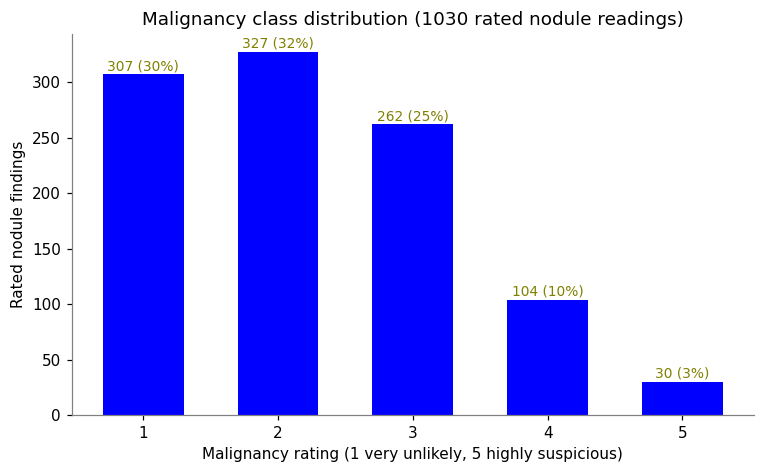

Always predicting the majority class, 5 classes: 31.7% accuracy
Always predicting benign, binary without the 3s: 82.6% accuracy
Always predicting benign, binary with 3 counted as benign: 87.0% accuracy
mean
1    230
2    279
3    182
4     60
5     14
Name: count, dtype: int64
Share of 4 and 5 with a mask: 15.5% of 857


In [22]:
class_counts = nodules["malignidade_rating"].value_counts().reindex([1.0, 2.0, 3.0, 4.0, 5.0]).astype(int)
total = class_counts.sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([1, 2, 3, 4, 5], class_counts.values, width=0.6, color=BLUE)
for bar, n in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 4, f"{n} ({n / total:.0%})", ha="center", fontsize=9, color=OLIVE)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Malignancy rating (1 very unlikely, 5 highly suspicious)")
ax.set_ylabel("Rated nodule findings")
ax.set_title(f"Malignancy class distribution ({total} rated nodule readings)")
plt.show()

benign, indeterminate, suspicious = class_counts[[1.0, 2.0]].sum(), class_counts[3.0], class_counts[[4.0, 5.0]].sum()
print(f"Always predicting the majority class, 5 classes: {class_counts.max() / total:.1%} accuracy")
print(f"Always predicting benign, binary without the 3s: {benign / (benign + suspicious):.1%} accuracy")
print(f"Always predicting benign, binary with 3 counted as benign: {(benign + indeterminate) / total:.1%} accuracy")

# Same distribution per unique nodule, averaging readers and rounding to the nearest class
print(pd.cut(per_lesion["mean"], [0, 1.5, 2.5, 3.5, 4.5, 5], labels=[1, 2, 3, 4, 5]).value_counts().sort_index())

# And restricted to readings that have a segmentation
with_mask = nodules[~placeholder]["malignidade_rating"].dropna()
print(f"Share of 4 and 5 with a mask: {(with_mask >= 4).mean():.1%} of {len(with_mask)}")

## 6. Nodules and non-nodules

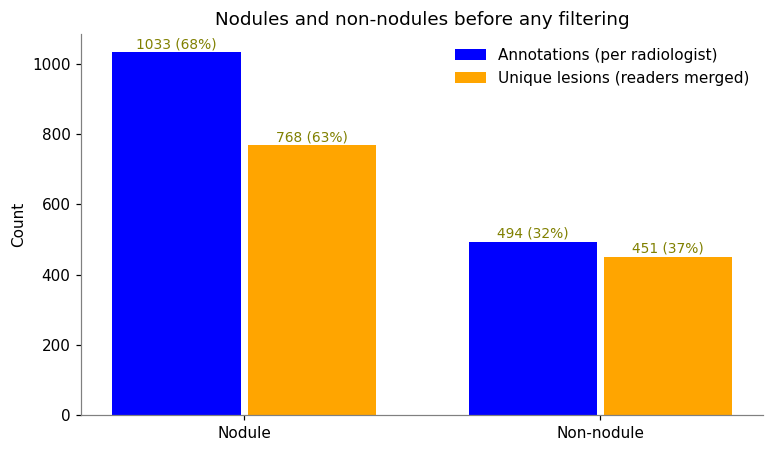

CT scans in LNDb: 294
Training scans: 236 (58 withheld for the challenge test set)
Training scans with at least one annotation: 229
Training scans with at least one nodule: 212
readers per scan
1     59
2    110
3     67
Non-nodule lesions marked by a single reader: 408
Rated, segmented nodules: 857 readings, 622 unique lesions, 204 scans


In [23]:
# Two levels: individual annotations (one row per radiologist and finding) and unique lesions after
# merging readers in trainNodules_gt.csv
per_annotation = df["categoria"].value_counts().reindex([1, 0])
per_lesion_cat = train_nodules_gt["Nodule"].value_counts().reindex([1, 0])

x = np.arange(2)
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
for offset, series, color, label in [(-width / 2 - 0.01, per_annotation, BLUE, "Annotations (per radiologist)"),
                                     (width / 2 + 0.01, per_lesion_cat, ORANGE, "Unique lesions (readers merged)")]:
    bars = ax.bar(x + offset, series.values, width, color=color, label=label)
    for bar, n in zip(bars, series.values):
        ax.text(bar.get_x() + bar.get_width() / 2, n + 12, f"{n} ({n / series.sum():.0%})",
                ha="center", fontsize=9, color=OLIVE)
ax.set_xticks(x, ["Nodule", "Non-nodule"])
ax.set_ylabel("Count")
ax.set_title("Nodules and non-nodules before any filtering")
ax.legend(frameon=False)
plt.show()

print("CT scans in LNDb:", len(acq))
print("Training scans:", len(train_cts), f"({len(acq) - len(train_cts)} withheld for the challenge test set)")
print("Training scans with at least one annotation:", df["scan_id"].nunique())
print("Training scans with at least one nodule:", nodules["scan_id"].nunique())
print(train_cts["RadN"].value_counts().sort_index().rename_axis("readers per scan").rename("scans").to_string())
print("Non-nodule lesions marked by a single reader:",
      (train_nodules_gt.loc[train_nodules_gt["Nodule"] == 0, "RadID"].astype(str).str.count(",") == 0).sum())

# What is left for a malignancy classifier that needs a mask
usable = lesion_readings[lesion_readings["malignancy"].notna() & ~np.isclose(lesion_readings["diametro_mm"], 3.0)]
print(f"Rated, segmented nodules: {len(usable)} readings, {usable['lesion'].nunique()} unique lesions, "
      f"{usable['LNDbID'].nunique()} scans")

Before any filtering, the LNDb training set has 236 CT scans (the other 58 of the 294 were withheld for the challenge test set). 229 of them have at least one annotation and 212 have at least one nodule, so only 7 scans are completely empty. Most scans were read by more than one radiologist: 59 by one, 110 by two and 67 by three.

At the annotation level there are 1527 rows, 1033 nodules (68%) and 494 non-nodules (32%). After merging readers there are 1219 unique lesions, 768 nodules and 451 non-nodules, so the non-nodule share goes up to 37%. The shift makes sense. Nodules are more often marked by several readers.

The main practical point is that 1527 rows are far from 1527 training examples for a malignancy classifier. Taking only nodules leaves 1033 readings, dropping the 3 unrated ones leaves 1030, and if the features need a mask, dropping the under 3 mm findings leaves 857 readings. Grouped by lesion, that becomes 622 unique nodules from 204 patients, and only about 12% of them average above 3.5, which puts them on the suspicious side. At the moment we consider that the non-nodules should not disappear from the project though. 

## Decisions taken

## 7. Formalising the malignancy label per nodule

This section aims to turn the previous discussions into a single table, `nodule_labels`, with one row per unique nodule, and is meant to be aggregated with LIDC.

The table keeps three views of the same rating side by side instead of picking one and throwing the others away.


1 - `malignancy_mean` is the continuous mean malignancy across every radiologist who rated a given nodule, and it is the version we intend to train on. 


2 - `label_ternary` buckets the same mean into benign / indeterminate / malignant at the 2.5 / 3.5. Our goal with this relates more with the possibility of showing results rather than training the model.


3 - `label_binary` is the strict two class view which may be useful to compare with some literature results, for instance. One important aspect we made sure to include was the way to handle the "indeterminate" in order to make sure it was an explicit decision. For indeterminate nodules this column is marked with NaN. This specifically means that if we want to ignore this category for any model we will have to make such decision deliberatly and not something that happens silently.

We are keeping the class 3 nodules in `malignancy_mean` and `label_ternary`, rather than dropping them the way a plain 1-2-vs-4-5 binary pipeline would, because the literature built specifically around this labelling problem treats exclusion as the weaker default, not the safer one. Taking into consideration all that we have learnt about the topic we consider the idea of disconsidering this data.  Work designed around LIDC's "unsure" nodules frames plain exclusion as the problem it exists to solve: existing pipelines "discard unsure nodules and simply deal with a binary classification", which is exactly the data we want to keep, and ordinal regression over the full scale is proposed as the fix (webgrafia Lei et al., 2020). The same critique, together with a demonstration of how much reported performance shifts once excluded nodules are handled differently, appears in Zhang et al. (2022). Separately, and more about the discipline of documenting this decision than about the aggregation itself, a case study built around this exact family of datasets shows that different published sample-selection rules produce subsets of very different difficulty, to the point that "on a more challenging sample selection, on the same database, the more advanced models underperform with respect to very simple baseline methods" (Baltatzis et al., 2021). That is the reason every derived column below is computed explicitly, with its own printed counts, rather than folded into an early filter: whichever threshold ends up used has to be visible and defensible on its own, not an accident of how the table was assembled.

In [ ]:
# One row per unique nodule (train_nodules_gt with Nodule == 1), carrying position, volume, and the
# malignancy statistics already computed per lesion in section 4 (per_lesion). Non-nodules cannot enter
# this table: both per_lesion and the .loc filter below start from Nodule == 1 only.
nodule_labels = (train_nodules_gt.loc[train_nodules_gt["Nodule"] == 1,
                                       ["LNDbID", "FindingID", "x", "y", "z", "Volume"]]
                  .join(per_lesion, how="left")
                  .rename(columns={"mean": "malignancy_mean", "count": "n_raters"}))
nodule_labels.insert(0, "dataset", "LNDb")

assert (train_nodules_gt.loc[nodule_labels.index, "Nodule"] == 1).all()  # non-nodules cannot be in here
n_non_nodule = (train_nodules_gt["Nodule"] == 0).sum()
print(f"{len(nodule_labels)} nodule lesions kept, {n_non_nodule} non-nodule lesions excluded, "
      f"out of {len(train_nodules_gt)} unique lesions in trainNodules_gt.csv")
print(f"{nodule_labels['malignancy_mean'].isna().sum()} nodules have no rated reading and stay unlabelled")

# The 2.5 / 3.5 split already used informally in section 5, made explicit and applied to the continuous
# per-nodule mean rather than to individual readings.
nodule_labels["label_ternary"] = pd.cut(nodule_labels["malignancy_mean"], bins=[0, 2.5, 3.5, 5],
                                        labels=["benign", "indeterminate", "malignant"])

# The strict two class view some baselines will want. Indeterminate nodules get NaN here, not a dropped
# row: nodule_labels keeps every nodule, and excluding the indeterminate band for a given model becomes
# an explicit nodule_labels["label_binary"].notna() filter at that model's own boundary.
nodule_labels["label_binary"] = nodule_labels["label_ternary"].map({"benign": 0, "malignant": 1})

print("\nTernary label:\n", nodule_labels["label_ternary"].value_counts(dropna=False).to_string())
print("\nBinary label (NaN = indeterminate or unrated):\n",
      nodule_labels["label_binary"].value_counts(dropna=False).to_string())

n_rated = nodule_labels["malignancy_mean"].notna().sum()
n_indeterminate = (nodule_labels["label_ternary"] == "indeterminate").sum()
print(f"\n{n_indeterminate} of {n_rated} rated nodules ({n_indeterminate / n_rated:.1%}) sit in the "
      f"indeterminate band; a plain 3-vs-rest exclusion rule would have dropped all of them from training")

nodule_labels.to_csv("lndb_nodule_labels.csv", index_label="lesion")
nodule_labels.head()

The three columns are views of one number, not three different labelling schemes. `malignancy_mean` is what should feed a model whose output also has to serve as the competition's 1 to 5 prediction, since it keeps the full ordinal scale. `label_ternary` and `label_binary` are read off that same number afterwards, purely for reporting: computing balanced accuracy, F1 or a confusion matrix against `label_ternary`, or against `label_binary.notna()` for a stricter two class comparison, gives us numbers that a clinician, or the accuracy and AUC figures quoted in the related work section of the project brief, can actually be read against, without ever having trained on a version of the data missing a quarter of its nodules.

One thing worth checking once this cell has actually run against a consistent `lndb_processado.csv`: 25% of individual readings are rated 3 (section 5), but that reading level share is not the same number as the share of nodules whose `malignancy_mean` lands in the indeterminate band. Averaging pulls single-reader nodules toward whatever that one reader said, so a nodule read once as a 3 stays there, while a nodule read by several radiologists only ends up near 3 if their ratings disagree in a way that happens to average out, or if several of them independently land close to the middle. The count printed above the ternary breakdown is the number that actually matters for deciding how much data an exclusion rule would cost, not the reading level 25%, and it is worth re-checking whenever `per_lesion` changes.